# 03 - EDA (Exploratory Data Analysis) — ONLY on `train_raw`

**Mandatory rules:**
- Only reads and analyses **`data_processed/train_raw.csv`**. **Under no circumstances read `val_raw.csv` or `test_raw.csv`** here, to avoid data leakage / data snooping — all decisions about variables, thresholds, polynomial degree... are only allowed to "see" the training set.
- Data normalisation (missing, type casting, mapping...) in this notebook **serves only as temporary visualisation** on a copy `df_eda`, **NOT the official preprocessing pass** and **does NOT save any files/parameters** here. Official parameter fitting (median impute, outlier bounds, mean/std scale...) is performed under controlled conditions in `04_feature_engineering.ipynb` and saved in `src/preprocessing.py`.

**EDA objective:** understand the distribution of each variable, relationship (linear or non-linear) with the target variable `mpg`, degree of outliers, and multicollinearity among independent variables — as basis for selecting variables and choosing the **degree** suitable for Polynomial Regression in subsequent notebooks.

## 1. Environment setup & visualisation style
Only uses `pandas` / `numpy` / `matplotlib` / `seaborn` (seaborn is just a visualisation layer built on matplotlib, **not** a data processing/modelling tool like `sklearn`).

In [1]:
import os
# Import libraries - use ONLY pandas/numpy/matplotlib/seaborn (visualisation only), NOT sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

# --- Shared presentation style for the whole notebook: light background, subtle grid, clear font ---
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.02)
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#4a4a4a',
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.titlepad': 10,
    'axes.labelsize': 10.5,
    'grid.alpha': 0.35,
    'font.family': 'DejaVu Sans',
})

# Main colour palette used throughout the notebook (one "neutral" colour + 3 colours for origin)
COLOR_MAIN      = '#2A6F97'   # dark blue - default for histogram/scatter
COLOR_HIGHLIGHT = '#A63446'   # dark red - used for labels/warnings/outliers
COLOR_SECONDARY = '#588157'   # green - used as a secondary colour
PALETTE_ORIGIN = {1: '#2A6F97', 2: '#F4A259', 3: '#A63446'}   # 1=USA, 2=Europe, 3=Japan
ORIGIN_NAMES = {1: 'USA', 2: 'Europe', 3: 'Japan'}

TRAIN_PATH = '../data_processed/train_raw.csv'   # ONLY read train_raw, do not read val/test here

# --- Folder to export all EDA charts (figures) ---
REPORT_DIR = '../report'
os.makedirs(REPORT_DIR, exist_ok=True)

def save_fig(fig, filename, dpi=150):
    """Save a matplotlib Figure (or seaborn PairGrid/FacetGrid) to REPORT_DIR as PNG."""
    path = os.path.join(REPORT_DIR, filename)
    fig.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f'Saved figure: {path}')

print('Notebook presentation style set up.')

Notebook presentation style set up.


## 2. Load data & TEMPORARY light preprocessing for analysis
The steps below (normalising missing tokens, type-casting, word→number mappings...) only create a **temporary DataFrame copy** (`df_eda`) for visualisation/statistics in this notebook — the logic mirrors `clean_raw()` which will be officially implemented in `src/preprocessing.py`, but **no parameters here are learned or saved**.

In [2]:
# Read train_raw keeping the raw string form (don't let pandas interpret anything)
df_raw = pd.read_csv(TRAIN_PATH, dtype=str, keep_default_na=False, na_values=[])
print(f'Shape of train_raw: {df_raw.shape}')
df_raw.head()

Shape of train_raw: (322, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,31.5,4,98.0,N/A,2045,18.5,77.0,3,honda accord cvcc
1,24.5,4,151.0,88,2740,16.0,77.0,1,pontiac sunbird coupe
2,12.0,8,350.0,180,4499,12.5,73.0,1,oldsmobile vista cruiser
3,24.0,4,113.0,95,2372,15.0,70.0,3,TOYOTA CORONA MARK II
4,24.0,6,200.0,81,3012,17.6,1976.0,1,ford maverick


In [3]:
# --- Normalise the various missing-value tokens to real NaN (for EDA only) ---
missing_tokens = ['?', 'NA', 'N/A', 'na', 'n/a', 'unknown', 'Unknown', 'UNKNOWN',
                   'nan', 'NaN', 'NAN', 'null', 'NULL', 'None', 'none', '-', '--', '']

df_eda = df_raw.copy()
df_eda = df_eda.apply(lambda col: col.astype(str).str.strip())
df_eda = df_eda.replace({tok: np.nan for tok in missing_tokens})

print('NaN count after normalising the missing-value forms (for observation only):')
print(df_eda.isna().sum())

NaN count after normalising the missing-value forms (for observation only):
mpg              3
cylinders        0
displacement     0
horsepower      14
weight           0
acceleration     0
model year       0
origin           0
car name         0
dtype: int64


In [4]:
# --- Cast types + normalise formatting per column (logic mirrors clean_raw(), run temporarily here for EDA) ---

# weight: may have the 'lbs' unit attached -> strip the text, cast to numeric
df_eda['weight'] = (
    df_eda['weight'].astype(str).str.replace('lbs', '', case=False, regex=False).str.strip()
)
df_eda['weight'] = pd.to_numeric(df_eda['weight'], errors='coerce')

# acceleration: European decimal comma -> replace ',' with '.'
df_eda['acceleration'] = df_eda['acceleration'].astype(str).str.replace(',', '.', regex=False)
df_eda['acceleration'] = pd.to_numeric(df_eda['acceleration'], errors='coerce')

# horsepower: cast to numeric; negative or unrealistic values (>=1000) -> NaN
df_eda['horsepower'] = pd.to_numeric(df_eda['horsepower'], errors='coerce')
df_eda.loc[(df_eda['horsepower'] < 0) | (df_eda['horsepower'] >= 1000), 'horsepower'] = np.nan

# cylinders: word -> number
word_to_number = {'zero': 0, 'one': 1, 'two': 2, 'three': 3, 'four': 4,
                   'five': 5, 'six': 6, 'seven': 7, 'eight': 8, 'nine': 9}
def normalize_cylinders(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().lower()
    if s in word_to_number:
        return word_to_number[s]
    try:
        return float(s)
    except ValueError:
        return np.nan
df_eda['cylinders'] = df_eda['cylinders'].apply(normalize_cylinders)

# origin: mixed word/number -> unified code 1=USA, 2=Europe, 3=Japan
origin_word_to_code = {'usa': 1, 'us': 1, 'america': 1, 'europe': 2, 'eu': 2, 'japan': 3, 'jp': 3}
def normalize_origin(value):
    if pd.isna(value):
        return np.nan
    s = str(value).strip().lower()
    if s in origin_word_to_code:
        return origin_word_to_code[s]
    try:
        num = float(s)
        return num if num in (1.0, 2.0, 3.0) else np.nan
    except ValueError:
        return np.nan
df_eda['origin'] = df_eda['origin'].apply(normalize_origin)

# model year: 2 digits -> 4 digits (70 -> 1970); unrealistic year (e.g. 2199 from a data-entry error) -> NaN
# (identical to _normalize_model_year() in src/preprocessing.py, revisited in section 1.1 below)
def normalize_model_year(value):
    if pd.isna(value):
        return np.nan
    try:
        n = float(value)
    except ValueError:
        return np.nan
    n = 1900 + n if n < 100 else n
    if n < 1960 or n > 2030:
        return np.nan
    return n
df_eda['model year'] = df_eda['model year'].apply(normalize_model_year)

# mpg, displacement: cast to numeric; unrealistic mpg (e.g. 9999) -> NaN
for c in ['mpg', 'displacement']:
    df_eda[c] = pd.to_numeric(df_eda[c], errors='coerce')
df_eda.loc[df_eda['mpg'] > 200, 'mpg'] = np.nan

numeric_cols = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year', 'origin']
independent_vars = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year']

print('Temporary normalisation complete. Descriptive statistics:')
df_eda[numeric_cols].describe().T.round(2)

Temporary normalisation complete. Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
mpg,317.0,23.38,7.79,10.0,17.00,22.3,29.00,44.6
cylinders,322.0,5.47,1.72,3.0,4.00,4.0,8.00,8.0
displacement,322.0,194.32,104.11,68.0,105.00,151.0,293.25,455.0
horsepower,307.0,112.15,82.76,46.0,77.50,95.0,130.00,850.0
weight,322.0,2957.09,935.29,-2506.0,2228.50,2830.0,3627.50,5140.0
acceleration,322.0,15.57,2.81,8.0,13.92,15.5,17.00,24.8
model year,321.0,1976.07,3.64,1970.0,1973.00,1976.0,1979.00,1982.0
origin,322.0,1.58,0.81,1.0,1.00,1.0,2.00,3.0


> ⚠️ **Finding from EDA — gap in current `clean_raw()`:** column `weight` (see `min` in the statistics table above) has **negative** values, which are physically impossible (a car cannot have negative weight). The current `clean_raw()` in `src/preprocessing.py` **only handles the `'lbs'` suffix and casts to numeric** for `weight`, without a step to filter negative/unrealistic values as already done for `horsepower` (< 0 or ≥ 1000 → NaN) and `model year` (outside 1960–2030 → NaN).

In [5]:
n_weight_negative = int((df_eda['weight'] < 0).sum())
print(f'Rows with weight < 0 in train_raw: {n_weight_negative}')
if n_weight_negative > 0:
    print('\nExamples of rows with negative weight:')
    print(df_eda.loc[df_eda['weight'] < 0, ['weight', 'mpg', 'car name']].to_string(index=False))

Rows with weight < 0 in train_raw: 2

Examples of rows with negative weight:
 weight  mpg                    car name
  -1945 33.5       Datsun F-10 Hatchback
  -2506 23.0 toyouta corona mark ii (sw)


### 2.1 Overview of missing values
Visualising % missing per column makes it immediately clear which columns are most "dirty" before diving into individual variables.

Saved figure: ../report\01_missing_values_rate.png


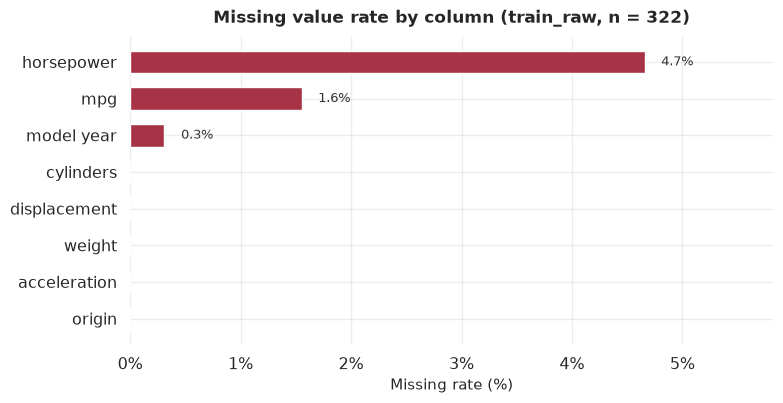

=> Insight: most columns have a small missing rate (a few %), suitable for median imputation
   instead of dropping whole columns/rows.


In [6]:
missing_pct = (df_eda[numeric_cols].isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(missing_pct.index[::-1], missing_pct.values[::-1],
                color=[COLOR_HIGHLIGHT if v > 0 else '#c9c9c9' for v in missing_pct.values[::-1]],
                edgecolor='white', height=0.62)
for b, v in zip(bars, missing_pct.values[::-1]):
    if v > 0:
        ax.text(v + 0.15, b.get_y() + b.get_height() / 2, f'{v:.1f}%', va='center',
                fontsize=9.5, color='#333333')
ax.set_xlabel('Missing rate (%)')
ax.set_title(f'Missing value rate by column (train_raw, n = {len(df_eda)})')
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlim(0, max(missing_pct.max() * 1.25, 5))
sns.despine(left=True, bottom=True)
plt.tight_layout()
save_fig(fig, '01_missing_values_rate.png')
plt.show()

print('=> Insight: most columns have a small missing rate (a few %), suitable for median imputation')
print('   instead of dropping whole columns/rows.')

## 3. Distribution of each numeric variable + Skewness
`|skew| > 1` is considered strongly skewed — a signal that `log-transform` may be needed before feeding into a linear/polynomial regression model. Each chart shows a histogram + density curve (KDE) and the median line to visually judge the degree of skewness.

Saved figure: ../report\02_numeric_distributions.png


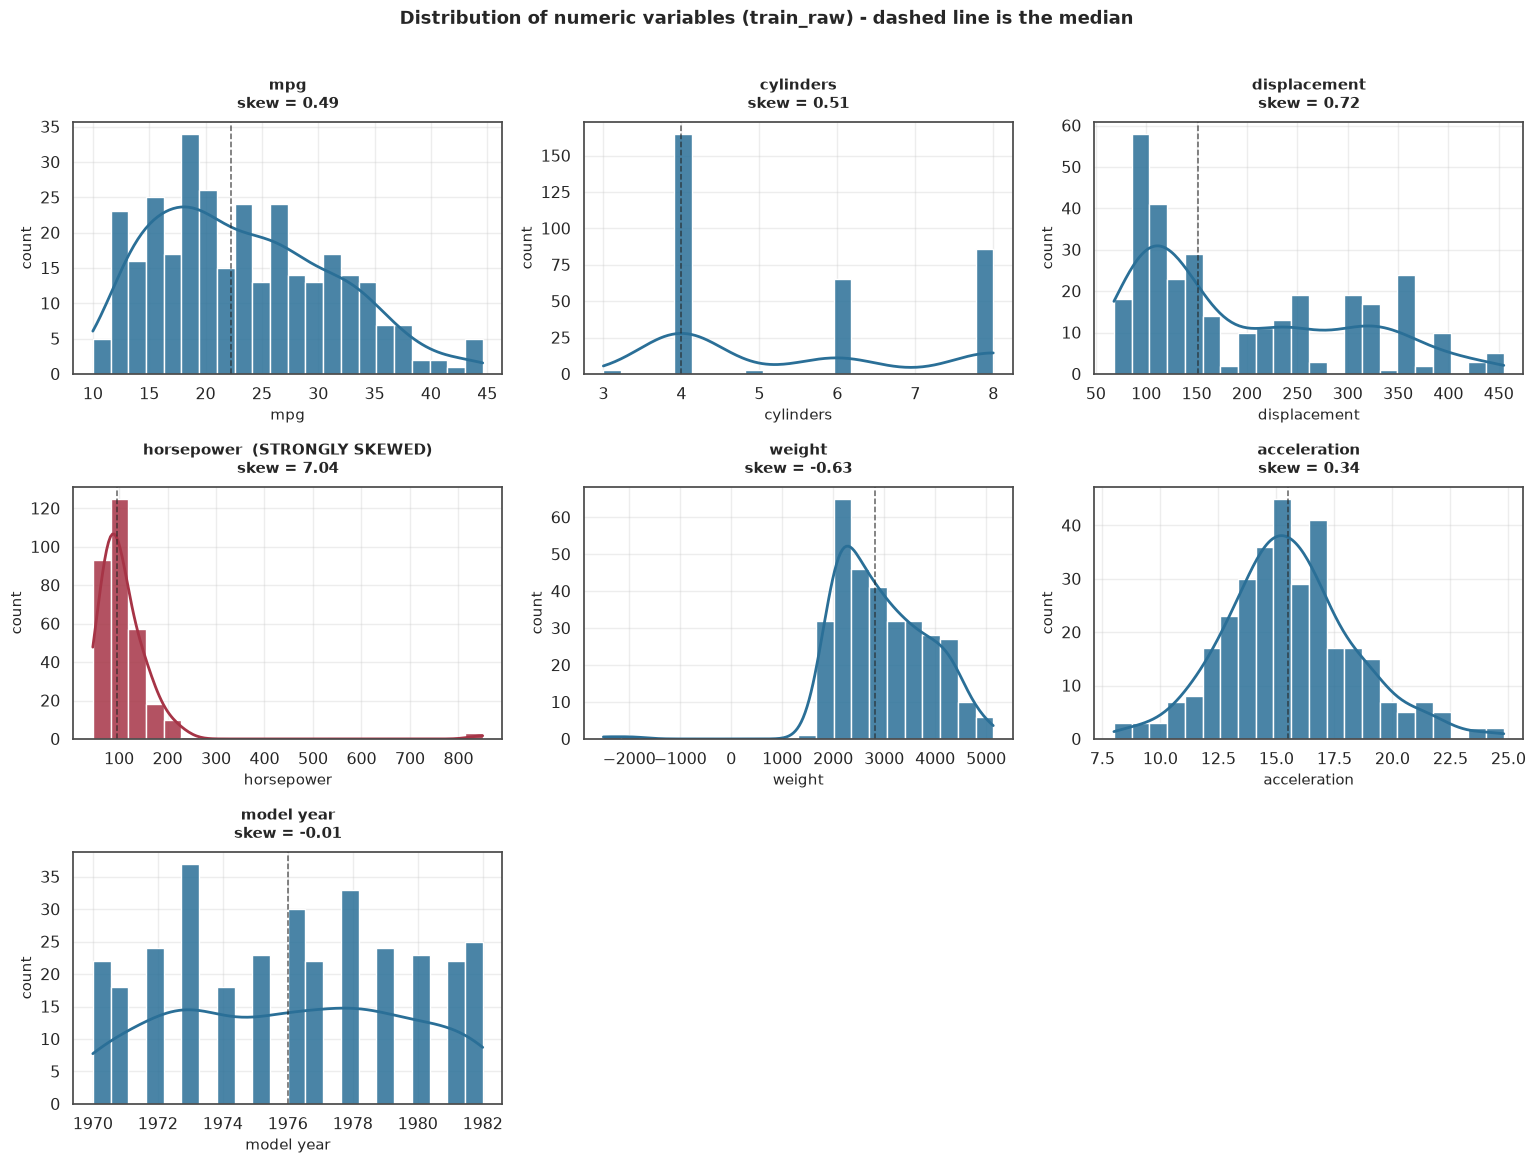

In [7]:
plot_vars = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model year']

fig, axes = plt.subplots(3, 3, figsize=(15.5, 11.5))
axes = axes.flatten()

skew_results = {}
for i, col in enumerate(plot_vars):
    values = df_eda[col].dropna()
    skew_val = values.skew()
    skew_results[col] = skew_val
    color = COLOR_HIGHLIGHT if abs(skew_val) > 1 else COLOR_MAIN

    sns.histplot(values, bins=22, color=color, edgecolor='white', alpha=0.85, kde=True,
                 line_kws={'linewidth': 2, 'color': '#222222'}, ax=axes[i])
    axes[i].axvline(values.median(), color='#222222', linestyle='--', linewidth=1.1, alpha=0.7)
    tag = '  (STRONGLY SKEWED)' if abs(skew_val) > 1 else ''
    axes[i].set_title(f'{col}{tag}\nskew = {skew_val:.2f}', fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('count')

for j in range(len(plot_vars), len(axes)):
    axes[j].axis('off')

fig.suptitle('Distribution of numeric variables (train_raw) - dashed line is the median',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig(fig, '02_numeric_distributions.png')
plt.show()

In [8]:
skew_df = (
    pd.Series(skew_results, name='skewness')
    .to_frame()
    .assign(strongly_skewed=lambda d: d['skewness'].abs() > 1)
    .sort_values('skewness', key=abs, ascending=False)
)
print('Skewness of each variable, sorted by |skew| descending:')
skew_df.round(3)

Skewness of each variable, sorted by |skew| descending:


,skewness,strongly_skewed
horsepower,7.042,True
displacement,0.721,False
weight,-0.631,False
cylinders,0.514,False
mpg,0.490,False
acceleration,0.341,False
model year,-0.006,False


## 4. Relationship between each independent variable and `mpg`
Each scatter is coloured by **origin** (USA / Europe / Japan) and includes a degree-2 trend line (`np.polyfit`) to directly observe **curved vs. straight** shapes — an important basis for choosing the polynomial degree at the train model step.

Saved figure: ../report\03_scatter_vs_mpg.png


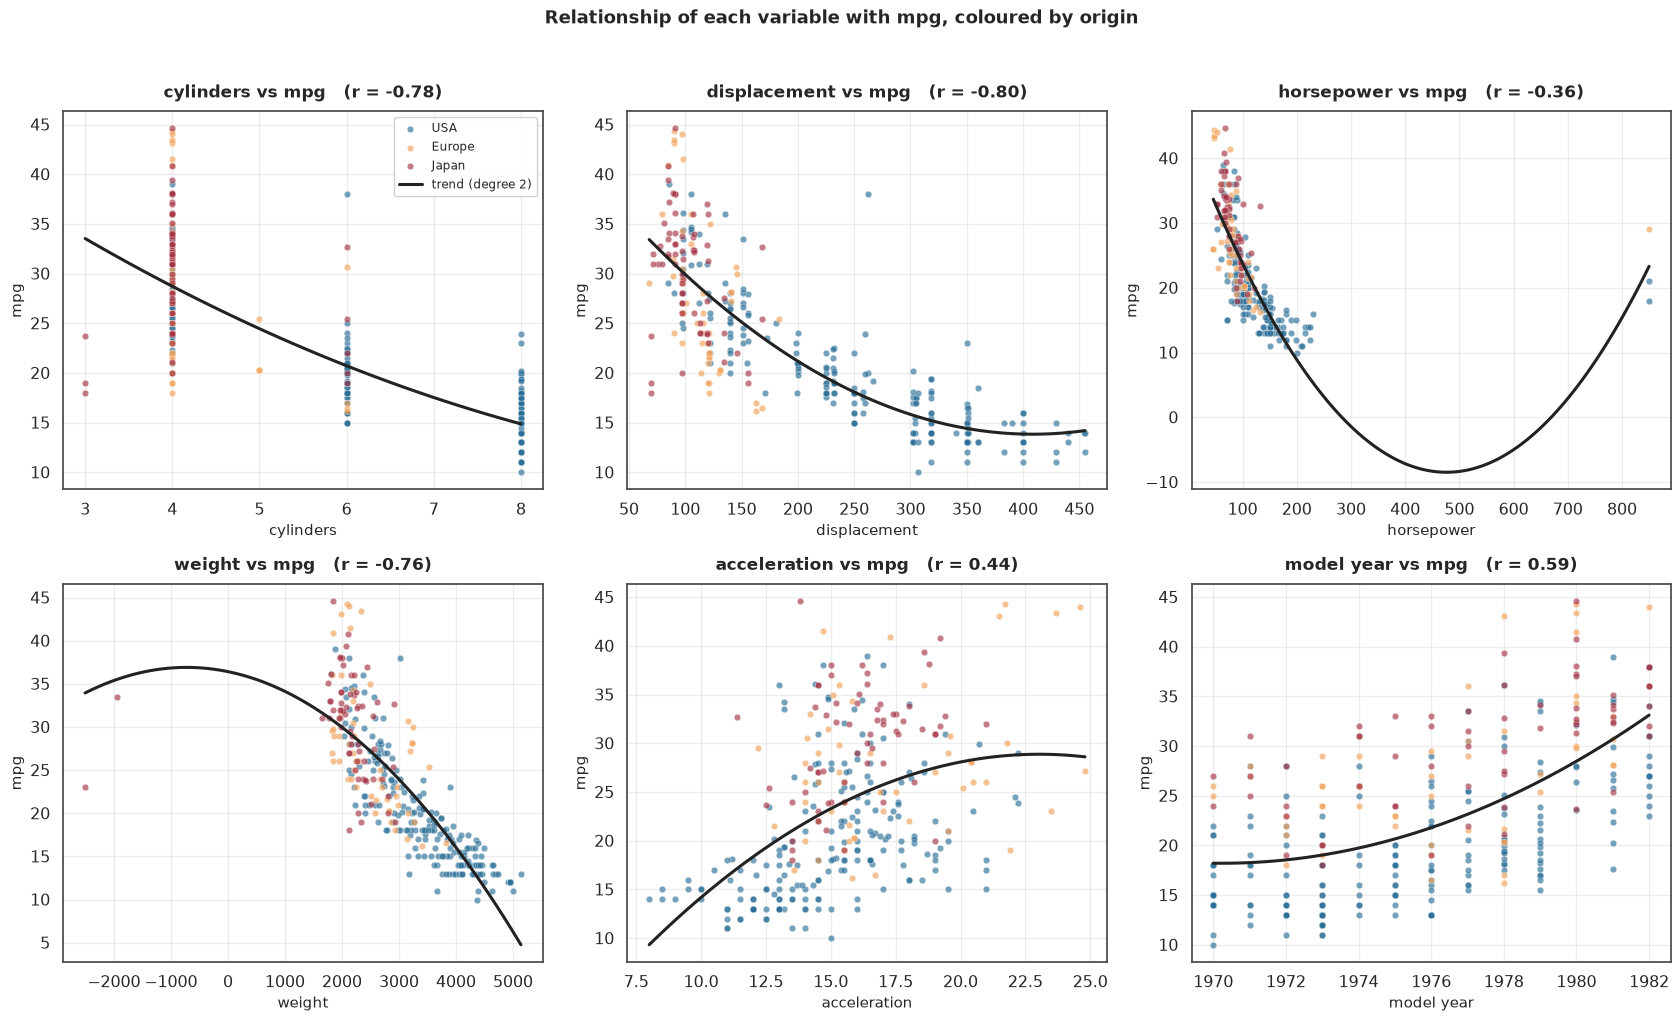

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.flatten()

for i, col in enumerate(independent_vars):
    ax = axes[i]
    sub = df_eda[[col, 'mpg', 'origin']].dropna()

    for origin_code, color in PALETTE_ORIGIN.items():
        group = sub[sub['origin'] == origin_code]
        ax.scatter(group[col], group['mpg'], s=22, alpha=0.65, color=color,
                   edgecolor='white', linewidth=0.3, label=ORIGIN_NAMES[origin_code])

    # degree-2 trend line (just to observe the shape, not an official model)
    x_sorted = np.linspace(sub[col].min(), sub[col].max(), 100)
    coef = np.polyfit(sub[col], sub['mpg'], 2)
    ax.plot(x_sorted, np.polyval(coef, x_sorted), color='#222222', linewidth=2.2,
            linestyle='-', label='trend (degree 2)')

    r = sub[col].corr(sub['mpg'])
    ax.set_xlabel(col)
    ax.set_ylabel('mpg')
    ax.set_title(f'{col} vs mpg   (r = {r:.2f})')

axes[0].legend(fontsize=8.5, loc='upper right', framealpha=0.9)
fig.suptitle('Relationship of each variable with mpg, coloured by origin', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig(fig, '03_scatter_vs_mpg.png')
plt.show()

**Observation:**
- `weight`, `displacement`, `horsepower`: strong negative correlation with `mpg`, and the degree-2 trend line shows significant curvature compared to a straight line → **polynomial degree 2 is more appropriate than degree 1 (pure linear)**.
- `cylinders`: relationship decreases in steps (discrete variable 3/4/5/6/8) rather than smoothly — still clearly decreases as cylinder count increases.
- `acceleration`: scattered point cloud, trend line nearly flat → **weak** correlation.
- `model year`: fairly steady **upward trend** over time, degree-2 curve close to a straight line → nearly linear relationship.
- Colour by `origin` reveals an additional insight: at the same `weight`/`horsepower` level, **Japan** (red) and **Europe** (orange) cars tend to occupy higher `mpg` regions than **USA** (blue) cars.

## 5. Correlation heatmap and correlation with `mpg`
Computed with `DataFrame.corr()` from pandas (Pearson correlation).
`|r|`:** `< 0.3` weak · `0.3 - 0.5` moderate · `>= 0.5` strong.

Saved figure: ../report\04_correlation_heatmap_all.png


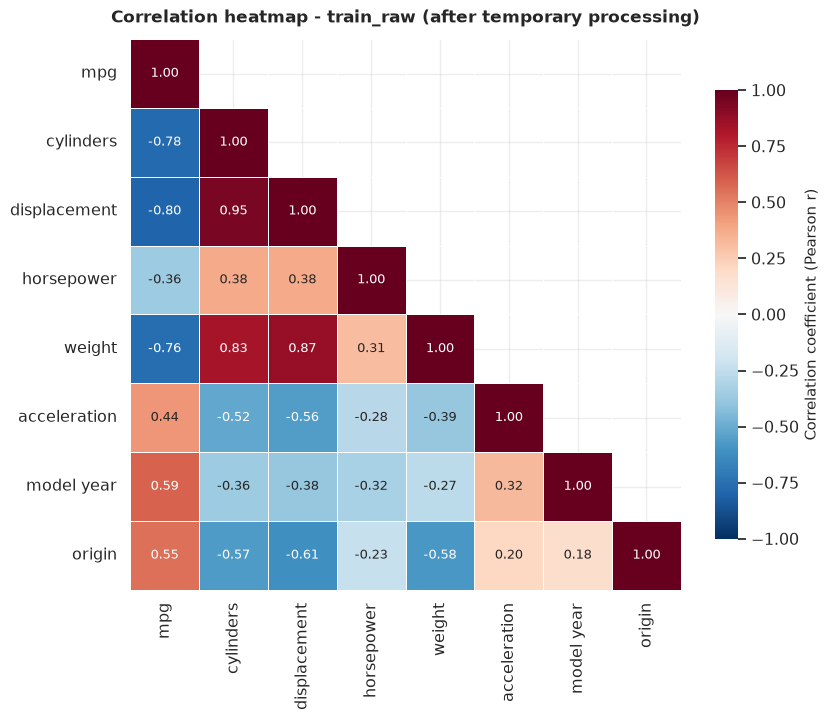

In [10]:
corr_matrix = df_eda[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8.5, 7.2))
sns.heatmap(corr_matrix, mask=mask, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'fontsize': 9}, linewidths=0.6,
            linecolor='white', cbar_kws={'label': 'Correlation coefficient (Pearson r)', 'shrink': 0.8},
            square=True, ax=ax)
ax.set_title('Correlation heatmap - train_raw (after temporary processing)', pad=12)
plt.tight_layout()
save_fig(fig, '04_correlation_heatmap_all.png')
plt.show()

Saved figure: ../report\05_correlation_with_mpg.png


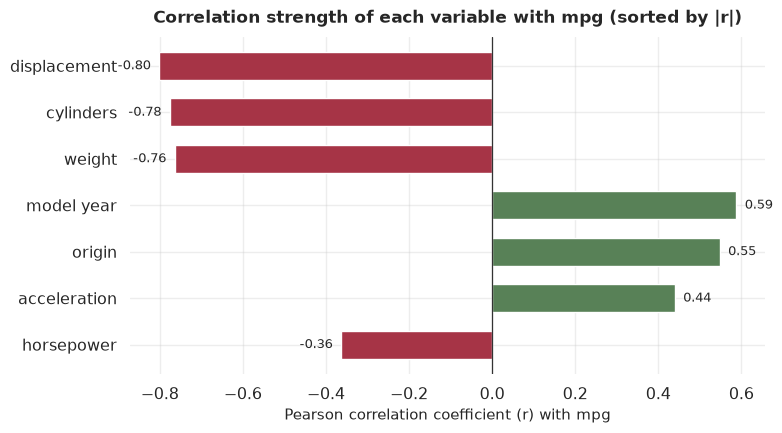

Correlation coefficients with mpg, sorted by |r| descending:


,r_with_mpg,abs_r,strength
displacement,-0.802,0.802,strong
cylinders,-0.776,0.776,strong
weight,-0.765,0.765,strong
model year,0.588,0.588,strong
origin,0.548,0.548,strong
acceleration,0.440,0.440,moderate
horsepower,-0.364,0.364,moderate


In [11]:
mpg_correlation = (
    corr_matrix['mpg'].drop('mpg')
    .to_frame('r_with_mpg')
    .assign(abs_r=lambda d: d['r_with_mpg'].abs())
    .sort_values('abs_r', ascending=False)
)

def classify_strength(r):
    if r >= 0.5:
        return 'strong'
    elif r >= 0.3:
        return 'moderate'
    return 'weak'

mpg_correlation['strength'] = mpg_correlation['abs_r'].apply(classify_strength)

fig, ax = plt.subplots(figsize=(8, 4.5))
bar_colors = mpg_correlation['r_with_mpg'].apply(lambda r: COLOR_HIGHLIGHT if r < 0 else COLOR_SECONDARY)
bars = ax.barh(mpg_correlation.index[::-1], mpg_correlation['r_with_mpg'][::-1],
               color=bar_colors[::-1], edgecolor='white', height=0.6)
for b, v in zip(bars, mpg_correlation['r_with_mpg'][::-1]):
    ax.text(v + (0.02 if v >= 0 else -0.02), b.get_y() + b.get_height() / 2, f'{v:.2f}',
            va='center', ha='left' if v >= 0 else 'right', fontsize=9.5)
ax.axvline(0, color='#333333', linewidth=0.9)
ax.set_xlabel('Pearson correlation coefficient (r) with mpg')
ax.set_title('Correlation strength of each variable with mpg (sorted by |r|)')
sns.despine(left=True, bottom=True)
plt.tight_layout()
save_fig(fig, '05_correlation_with_mpg.png')
plt.show()

print('Correlation coefficients with mpg, sorted by |r| descending:')
mpg_correlation.round(3)

## 6. Outlier detection: `horsepower`, `weight`, `mpg`
Using the standard IQR rule: `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`. Combines **violin + box + individual outlier points** to simultaneously see the distribution shape and identify exactly which points are flagged as anomalous.

Saved figure: ../report\06_outliers_boxplot.png


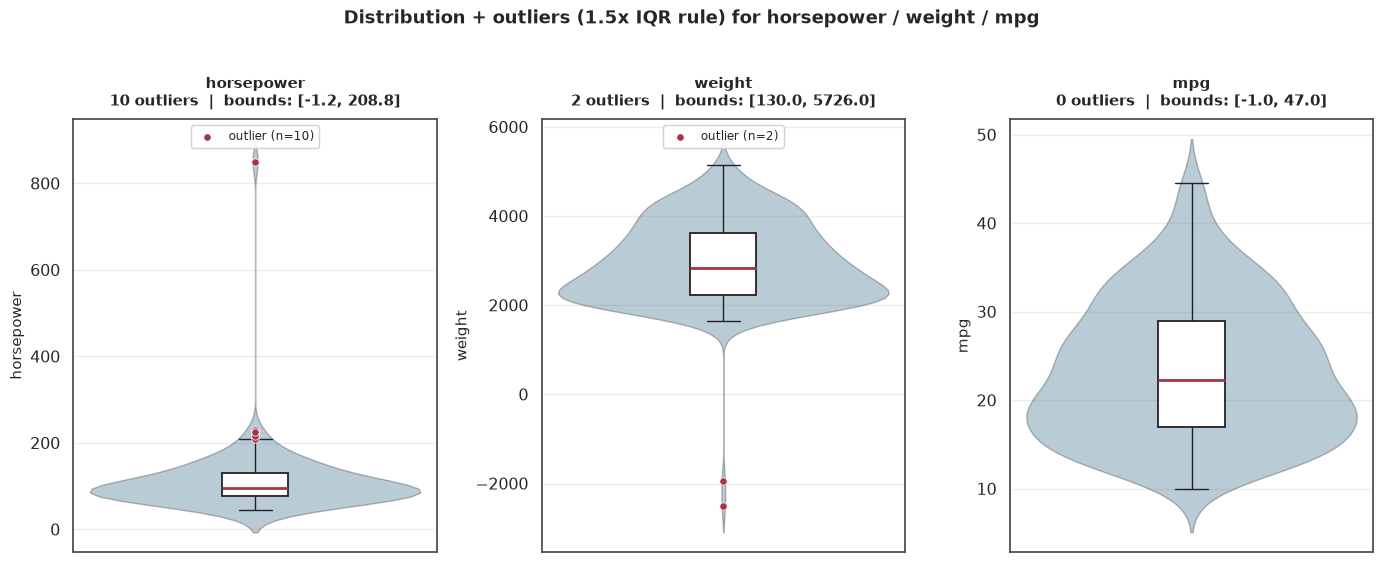

column              lower        upper    n_outlier
horsepower          -1.25       208.75           10
weight             130.00      5726.00            2
mpg                 -1.00        47.00            0


In [12]:
def _iqr_bounds(series):
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return lower, upper, int(mask.sum()), mask

outlier_check_cols = ['horsepower', 'weight', 'mpg']
outlier_results = {}

fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
for i, col in enumerate(outlier_check_cols):
    ax = axes[i]
    lower, upper, count, mask = _iqr_bounds(df_eda[col])
    outlier_results[col] = mask

    values = df_eda[col].dropna()
    sns.violinplot(y=values, ax=ax, color=COLOR_MAIN, alpha=0.35, inner=None, linewidth=1)
    sns.boxplot(y=values, ax=ax, width=0.16, color='white',
                boxprops={'edgecolor': '#222222', 'linewidth': 1.3},
                medianprops={'color': COLOR_HIGHLIGHT, 'linewidth': 2},
                whiskerprops={'color': '#222222'}, capprops={'color': '#222222'},
                showfliers=False)
    outlier_points = df_eda.loc[mask, col].dropna()
    ax.scatter(np.zeros(len(outlier_points)), outlier_points, color=COLOR_HIGHLIGHT, s=28, zorder=5,
               edgecolor='white', linewidth=0.5, label=f'outlier (n={count})')

    ax.set_title(f'{col}\n{count} outliers  |  bounds: [{lower:.1f}, {upper:.1f}]', fontsize=10.5)
    ax.set_xlabel('')
    if count > 0:
        ax.legend(loc='upper center', fontsize=8.5, framealpha=0.9)

fig.suptitle('Distribution + outliers (1.5x IQR rule) for horsepower / weight / mpg',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig(fig, '06_outliers_boxplot.png')
plt.show()

print(f'{"column":<12} {"lower":>12} {"upper":>12} {"n_outlier":>12}')
for col in outlier_check_cols:
    lower, upper, count, _ = _iqr_bounds(df_eda[col])
    print(f'{col:<12} {lower:>12.2f} {upper:>12.2f} {count:>12}')

In [13]:
for col in outlier_check_cols:
    mask = outlier_results[col]
    if mask.sum() > 0:
        print(f'\nExamples of outlier rows in column "{col}":')
        print(df_eda.loc[mask, [col, 'mpg', 'car name']].head(5).to_string(index=False))


Examples of outlier rows in column "horsepower":
 horsepower  mpg           car name
      850.0 21.0      ford maverick
      215.0 14.0  PLYMOUTH FURY III
      230.0 16.0 pontiac grand prix
      220.0 14.0   chevrolet impala
      210.0 11.0         dodge d200

Examples of outlier rows in column "weight":
 weight  mpg                    car name
  -1945 33.5       Datsun F-10 Hatchback
  -2506 23.0 toyouta corona mark ii (sw)


## 7. Check multicollinearity among independent variables
Independent variable pairs with `|r| > 0.8` — if both variables (especially at high degree) are included in Polynomial Regression simultaneously, the model is prone to multicollinearity and unstable regression coefficients.

Saved figure: ../report\07_correlation_independent_vars.png


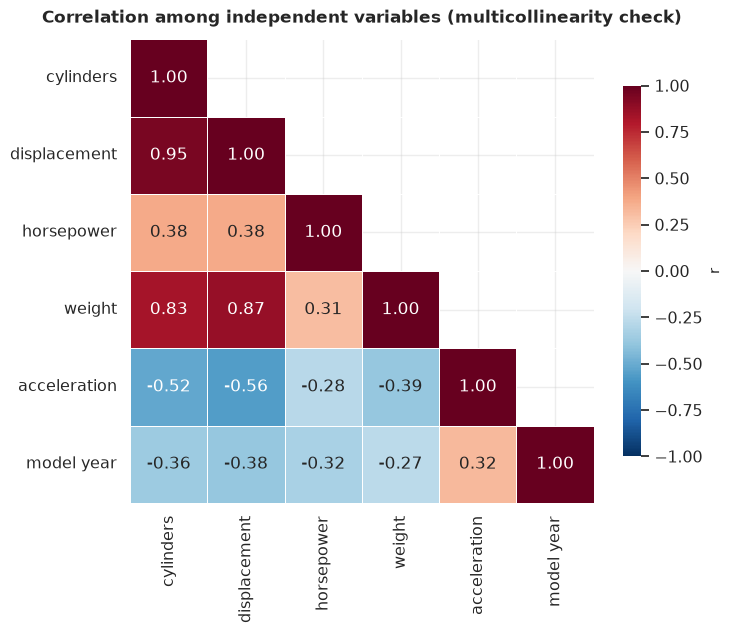

Number of variable pairs with |r| > 0.8 (strong multicollinearity risk): 3


,var_1,var_2,r
0,cylinders,displacement,0.949
2,displacement,weight,0.869
1,cylinders,weight,0.832


In [14]:
corr_independent = df_eda[independent_vars].corr()
mask_upper = np.triu(np.ones_like(corr_independent, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 6.3))
sns.heatmap(corr_independent, mask=mask_upper, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', linewidths=0.6, linecolor='white',
            cbar_kws={'label': 'r', 'shrink': 0.8}, square=True, ax=ax)
ax.set_title('Correlation among independent variables (multicollinearity check)', pad=12)
plt.tight_layout()
save_fig(fig, '07_correlation_independent_vars.png')
plt.show()

high_corr_pairs = []
for i in range(len(independent_vars)):
    for j in range(i + 1, len(independent_vars)):
        c1, c2 = independent_vars[i], independent_vars[j]
        r = corr_independent.loc[c1, c2]
        if abs(r) > 0.8:
            high_corr_pairs.append({'var_1': c1, 'var_2': c2, 'r': round(r, 3)})

high_corr_df = (pd.DataFrame(high_corr_pairs).sort_values('r', key=abs, ascending=False)
               if high_corr_pairs else pd.DataFrame(columns=['var_1', 'var_2', 'r']))
print(f'Number of variable pairs with |r| > 0.8 (strong multicollinearity risk): {len(high_corr_pairs)}')
high_corr_df

## 8. Deep-dive: `mpg` by category group and over time
Two supplementary perspectives, not replacing the correlation analysis above but clarifying **group-level insights** that simple linear correlation coefficients tend to miss.

Saved figure: ../report\08_mpg_by_origin_cylinders.png


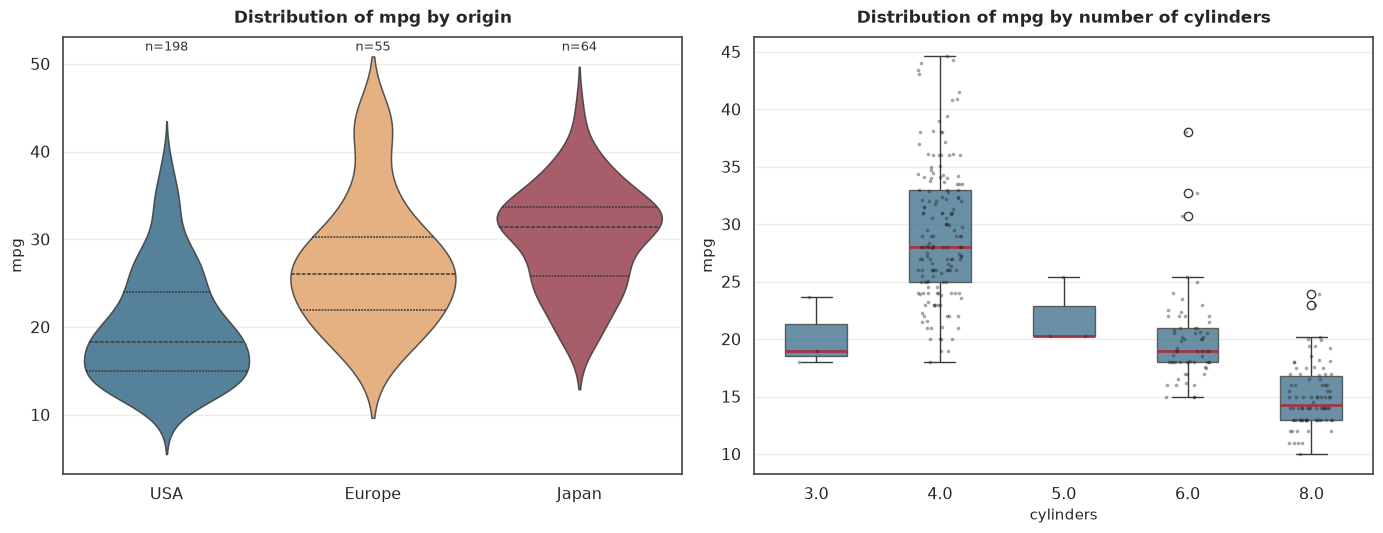

=> Insight: Japanese/European cars have a higher median mpg and fewer "gas-guzzling" cars
   (low mpg) than USA cars. mpg decreases almost monotonically with cylinder count -
   cylinders is a very strong discriminating variable for mpg.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 7a. mpg by origin
sub_o = df_eda.dropna(subset=['origin', 'mpg']).copy()
sub_o['origin_name'] = sub_o['origin'].map(ORIGIN_NAMES)
origin_order = ['USA', 'Europe', 'Japan']
sns.violinplot(data=sub_o, x='origin_name', y='mpg', order=origin_order, hue='origin_name',
               legend=False, ax=axes[0],
               palette={ORIGIN_NAMES[k]: v for k, v in PALETTE_ORIGIN.items()}, inner='quartile',
               linewidth=1.1, alpha=0.85)
origin_counts = sub_o['origin_name'].value_counts().reindex(origin_order)
for i, name in enumerate(origin_order):
    axes[0].text(i, axes[0].get_ylim()[1] * 0.97, f'n={origin_counts[name]}',
                 ha='center', fontsize=9, color='#333333')
axes[0].set_title('Distribution of mpg by origin')
axes[0].set_xlabel('')

# 7b. mpg by cylinders
sub_c = df_eda.dropna(subset=['cylinders', 'mpg']).copy()
cylinders_order = sorted(sub_c['cylinders'].unique())
sns.boxplot(data=sub_c, x='cylinders', y='mpg', order=cylinders_order, ax=axes[1],
            color=COLOR_MAIN, width=0.5,
            boxprops={'alpha': 0.75}, medianprops={'color': COLOR_HIGHLIGHT, 'linewidth': 2})
sns.stripplot(data=sub_c, x='cylinders', y='mpg', order=cylinders_order, ax=axes[1],
              color='#222222', size=2.6, alpha=0.4, jitter=0.18)
axes[1].set_title('Distribution of mpg by number of cylinders')
axes[1].set_xlabel('cylinders')

plt.tight_layout()
save_fig(fig, '08_mpg_by_origin_cylinders.png')
plt.show()

print('=> Insight: Japanese/European cars have a higher median mpg and fewer "gas-guzzling" cars')
print('   (low mpg) than USA cars. mpg decreases almost monotonically with cylinder count -')
print('   cylinders is a very strong discriminating variable for mpg.')

Saved figure: ../report\09_mpg_trend_by_year.png


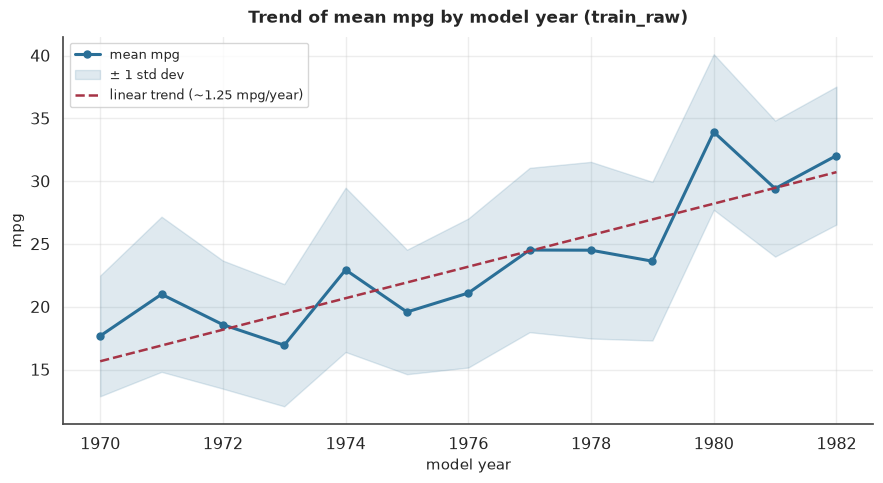

=> Insight: mean mpg increases by approximately 1.25 mpg per year over the observed period -
   this supports keeping "model year" as a meaningful, fairly linearly related variable.


In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
sub_y = df_eda.dropna(subset=['model year', 'mpg']).copy()
sub_y['year'] = sub_y['model year'].astype(int)

yearly_stats = sub_y.groupby('year')['mpg'].agg(['mean', 'std', 'count']).reset_index()

ax.plot(yearly_stats['year'], yearly_stats['mean'], marker='o', color=COLOR_MAIN,
        linewidth=2.2, markersize=5, label='mean mpg')
ax.fill_between(yearly_stats['year'],
                 yearly_stats['mean'] - yearly_stats['std'].fillna(0),
                 yearly_stats['mean'] + yearly_stats['std'].fillna(0),
                 color=COLOR_MAIN, alpha=0.15, label='± 1 std dev')

coef = np.polyfit(sub_y['year'], sub_y['mpg'], 1)
x_line = np.array([sub_y['year'].min(), sub_y['year'].max()])
ax.plot(x_line, np.polyval(coef, x_line), color=COLOR_HIGHLIGHT, linestyle='--', linewidth=1.8,
        label=f'linear trend (~{coef[0]:.2f} mpg/year)')

ax.set_xlabel('model year')
ax.set_ylabel('mpg')
ax.set_title('Trend of mean mpg by model year (train_raw)')
ax.legend(fontsize=9)
sns.despine()
plt.tight_layout()
save_fig(fig, '09_mpg_trend_by_year.png')
plt.show()

print(f'=> Insight: mean mpg increases by approximately {coef[0]:.2f} mpg per year over the observed period -')
print('   this supports keeping "model year" as a meaningful, fairly linearly related variable.')

### Composite pairplot (variables most correlated with `mpg`)
A final composite view: scatter matrix between `mpg` and the 3 variables with the highest `|r|` (`weight`, `displacement`, `horsepower`), coloured by `origin`, showing both pairwise correlation and group separation by vehicle origin simultaneously.

Saved figure: ../report\10_pairplot_top3_vars.png


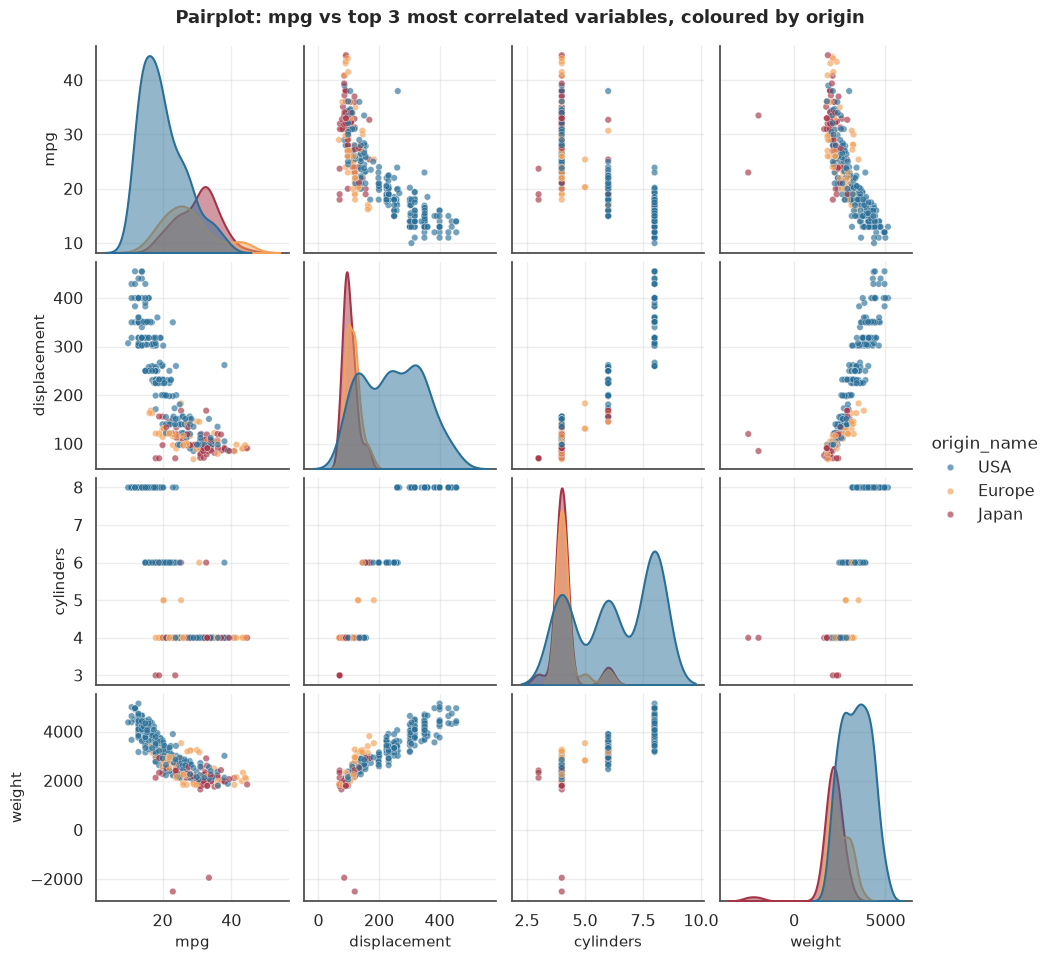

In [17]:
top_corr_vars = mpg_correlation.head(3).index.tolist()
sub_pair = df_eda.dropna(subset=top_corr_vars + ['mpg', 'origin']).copy()
sub_pair['origin_name'] = sub_pair['origin'].map(ORIGIN_NAMES)

g = sns.pairplot(
    sub_pair[['mpg'] + top_corr_vars + ['origin_name']],
    hue='origin_name', hue_order=origin_order,
    palette={ORIGIN_NAMES[k]: v for k, v in PALETTE_ORIGIN.items()},
    plot_kws={'alpha': 0.65, 's': 22, 'edgecolor': 'white', 'linewidth': 0.3},
    diag_kind='kde', diag_kws={'alpha': 0.5, 'linewidth': 1.5}, height=2.35,
)
g.fig.suptitle('Pairplot: mpg vs top 3 most correlated variables, coloured by origin', y=1.02, fontsize=13, fontweight='bold')
save_fig(g.fig, '10_pairplot_top3_vars.png')
plt.show()

## 9. EDA Conclusion
### Variables to keep
- Priority variables with `|r|` vs `mpg` at **moderate to strong** levels (section 4): typically `weight`, `displacement`, `horsepower`, `cylinders` — these also have clear physical relevance to fuel consumption.
- `model year` should be kept due to its nearly linear upward trend over time (section 7).
- `origin`, though its simple linear correlation with `mpg` is not the highest, group analysis in section 7 shows it clearly separates `mpg` clusters (Japan/Europe higher than USA) → still worth keeping as a feature.
- `acceleration` has the weakest correlation — can still be kept for additional signal, but is the lowest priority if feature reduction is needed.
### Variables to consider for log-transform
- Variables with `|skew| > 1` in section 2 (most clearly `horsepower`, skewed by a few unrealistic outlier values) are log-transform candidates before modelling, helping reduce outlier influence and normalise the distribution.
### On multicollinearity
- Section 6 lists independent variable pairs with `|r| > 0.8` (if any) — be careful when using high degree for these variables simultaneously, as it can make the `XᵀX` matrix near-singular in the custom Gauss-Jordan step.
### Data quality issues requiring additional handling
- **`weight` has negative values** (section 1.1) not yet filtered by `clean_raw()` — add a condition similar to `horsepower`/`model year` (e.g. `weight <= 0` → treat as `NaN`) in `src/preprocessing.py` before finalising `fit_preprocessing()`/`transform()` in notebook `04_...`, to prevent this unrealistic value from affecting the median impute / IQR bounds / mean-std scale of `weight`.